# Credit Card Fraud Detection

**Project Type:** Machine Learning + Deep Learning Classification Project
**Goal:** Predict whether a credit card transaction is **fraudulent** or **genuine**, using transaction details.

Credit card fraud is a huge problem for banks and customers. The tricky part of this dataset is that fraud is very rare - only about 0.17% of all transactions are fraud. This means a "lazy" model that just predicts "not fraud" every single time would still be 99.8% accurate, but it would be completely useless in real life! So in this project, accuracy is NOT the metric we care about. Instead we will focus on **Precision, Recall, F1-score and ROC-AUC**.

In this notebook I will:
1. Load and explore the dataset
2. Understand the class imbalance problem
3. Clean and preprocess the data
4. Train a few different **Machine Learning** models
5. Train a **Deep Learning** model (a simple Neural Network)
6. Compare all the models properly (not just using accuracy)
7. Save the best model so it can be used later in the Streamlit app


## 1. Importing the libraries we need

In [3]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [50]:
# basic libraries for handling data
import pandas as pd
import numpy as np

# libraries for plotting graphs
import matplotlib.pyplot as plt
import seaborn as sns

# machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report, roc_auc_score, roc_curve)

# deep learning library
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# to save the trained model
import pickle

sns.set_style("whitegrid")
%matplotlib inline

# just so results are the same every time we run this notebook
np.random.seed(42)
tf.random.set_seed(42)


## 2. Loading the dataset

This dataset contains transactions made by European cardholders in September 2013.
Because of confidentiality, most of the columns (`V1` to `V28`) are already the result of a
PCA transformation - so we don't know exactly what they mean, but we can still use them.
The only columns that are NOT transformed are `Time`, `Amount`, and `Class` (our target).


In [6]:
df = pd.read_csv("data/creditcard.csv")

print("Shape of the data:", df.shape)
df.head()


Shape of the data: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [8]:
# checking for missing values
df.isnull().sum().sum()


0

## 3. Understanding the class imbalance

This is the most important thing to understand about this dataset before we do anything else.


In [10]:
class_counts = df['Class'].value_counts()
print(class_counts)
print()
print("Percentage of Fraud transactions:", round(df['Class'].value_counts(normalize=True)[1] * 100, 3), "%")


Class
0    284315
1       492
Name: count, dtype: int64

Percentage of Fraud transactions: 0.173 %


C:\Users\anupu\AppData\Local\Temp\ipykernel_7632\2630776582.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df, palette='Set2')


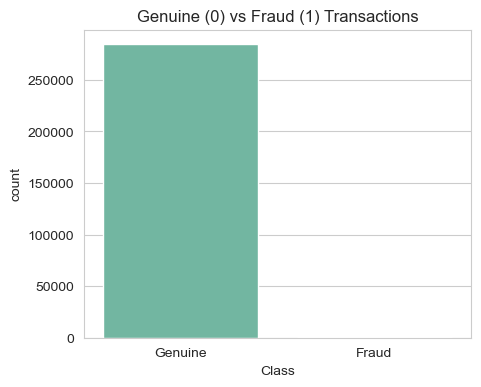

In [11]:
plt.figure(figsize=(5,4))
sns.countplot(x='Class', data=df, palette='Set2')
plt.title('Genuine (0) vs Fraud (1) Transactions')
plt.xticks([0, 1], ['Genuine', 'Fraud'])
plt.show()


As we can see, out of 284,807 transactions only 492 are fraud. This is called a **highly imbalanced dataset**. We will keep this in mind when training and evaluating our models - we cannot just look at accuracy.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Transaction Amount: Fraud vs Genuine

C:\Users\anupu\AppData\Local\Temp\ipykernel_7632\809457064.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='Amount', data=df, showfliers=False, palette='Set2')


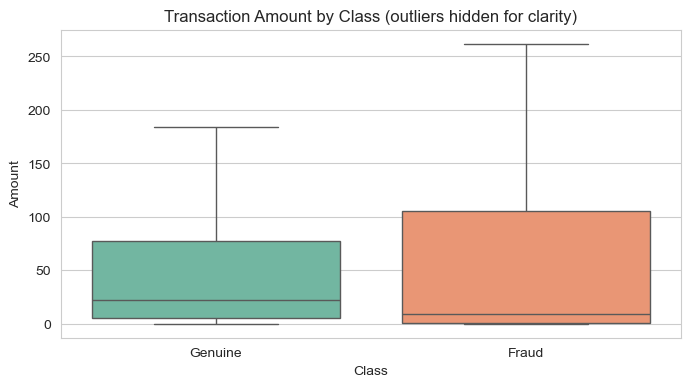

In [15]:
plt.figure(figsize=(8,4))
sns.boxplot(x='Class', y='Amount', data=df, showfliers=False, palette='Set2')
plt.xticks([0, 1], ['Genuine', 'Fraud'])
plt.title('Transaction Amount by Class (outliers hidden for clarity)')
plt.show()


In [16]:
print("Genuine transactions - Amount stats:")
print(df[df['Class']==0]['Amount'].describe())
print()
print("Fraud transactions - Amount stats:")
print(df[df['Class']==1]['Amount'].describe())


Genuine transactions - Amount stats:
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Fraud transactions - Amount stats:
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


### 4.2 Transaction Time pattern

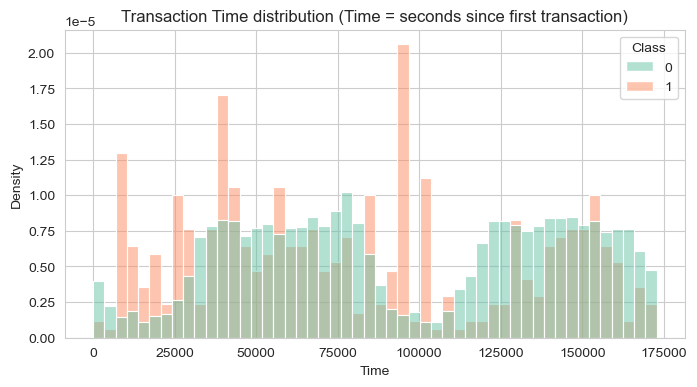

In [18]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x='Time', hue='Class', bins=50, stat='density', common_norm=False, palette='Set2')
plt.title('Transaction Time distribution (Time = seconds since first transaction)')
plt.show()


### 4.3 Correlation with Class

Since V1-V28 are PCA components, let's just check which ones are most correlated with fraud.

In [20]:
corr_with_class = df.corr()['Class'].sort_values()
print("Most negatively correlated with fraud:")
print(corr_with_class.head(5))
print()
print("Most positively correlated with fraud:")
print(corr_with_class.tail(6))


Most negatively correlated with fraud:
V17   -0.326481
V14   -0.302544
V12   -0.260594
V10   -0.216522
V16   -0.196539
Name: Class, dtype: float64

Most positively correlated with fraud:
V19      0.034783
V21      0.040413
V2       0.091289
V4       0.133448
V11      0.154876
Class    1.000000
Name: Class, dtype: float64


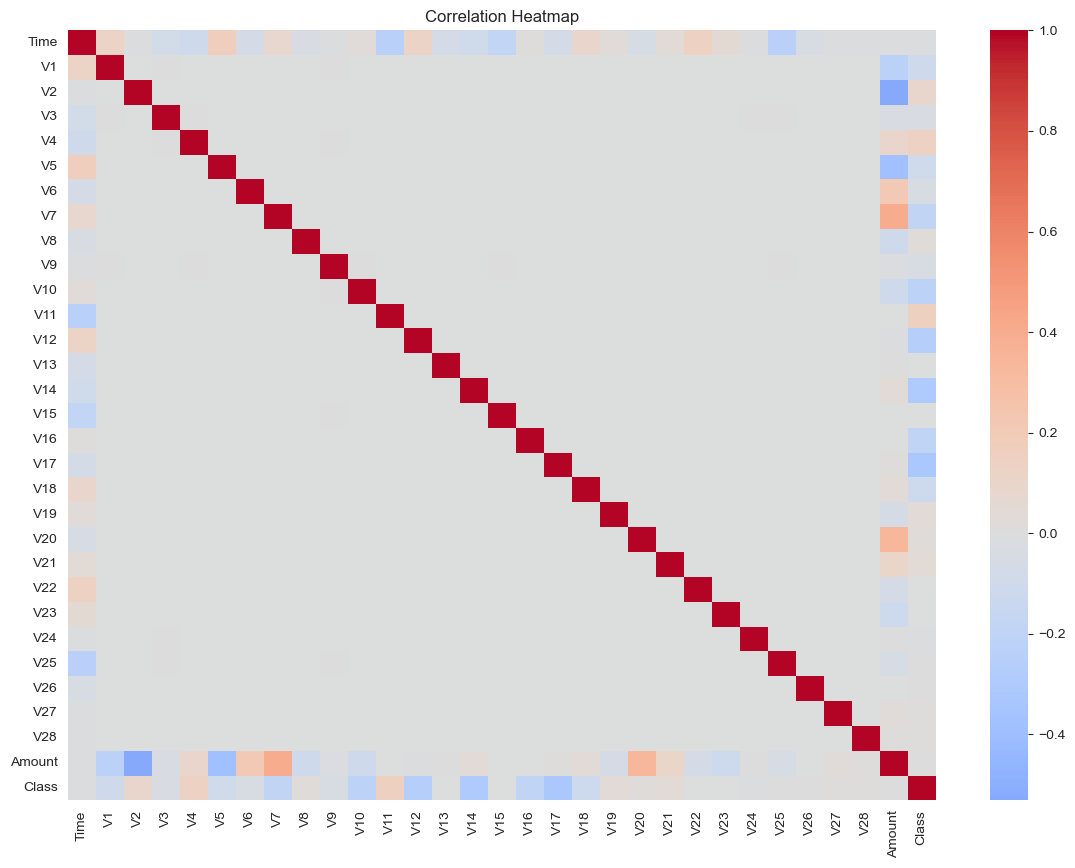

In [21]:
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()


**Observations from EDA:**
- Fraud transactions tend to have a slightly different amount distribution than genuine ones.
- Fraud is not concentrated at any particular time of day - it happens throughout.
- A few of the PCA columns (like V17, V14, V12, V10 and V11, V4) show a noticeably stronger correlation with fraud than the others.


## 5. Preparing the data for Machine Learning

`Time` and `Amount` are on very different scales compared to the V1-V28 columns (which are already scaled from PCA). So we scale `Time` and `Amount` using StandardScaler, same as we would scale any other numeric feature.


In [24]:
# NOTE: we use TWO SEPARATE scalers (one for Amount, one for Time).
# If we used just one scaler for both, it would only "remember" the last
# column it was fit on, and break later when we try to reuse it - so each
# column gets its own scaler object.

amount_scaler = StandardScaler()
time_scaler = StandardScaler()

df['scaled_amount'] = amount_scaler.fit_transform(df[['Amount']])
df['scaled_time'] = time_scaler.fit_transform(df[['Time']])

# drop the original unscaled columns, we'll use the scaled versions instead
df = df.drop(['Amount', 'Time'], axis=1)

df.head()


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V22,V23,V24,V25,V26,V27,V28,Class,scaled_amount,scaled_time
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0,0.244964,-1.996583
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0,-0.342475,-1.996583
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0,1.160686,-1.996562
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0,0.140534,-1.996562
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0,-0.073403,-1.996541


In [25]:
# rearrange so scaled_amount and scaled_time are at the front (just for readability)
cols = ['scaled_time', 'scaled_amount'] + [c for c in df.columns if c not in ['scaled_time','scaled_amount','Class']] + ['Class']
df = df[cols]
df.head()


,scaled_time,scaled_amount,V1,V2,V3,V4,V5,V6,V7,V8,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Class
0,-1.996583,0.244964,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0
1,-1.996583,-0.342475,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0
2,-1.996562,1.160686,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0
3,-1.996562,0.140534,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0
4,-1.996541,-0.073403,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0


## 6. Splitting the data into training and testing sets

We use `stratify=y` here - this makes sure that the small number of fraud cases are split proportionally between the training and test sets (otherwise we might accidentally end up with very few fraud examples in one of the sets).


In [27]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print()
print("Fraud cases in training set:", y_train.sum())
print("Fraud cases in test set:", y_test.sum())


Training set size: (227845, 30)
Testing set size: (56962, 30)

Fraud cases in training set: 394
Fraud cases in test set: 98


## 7. A helper function to evaluate our models

Since we will be training multiple models, let's write one function that prints out all the metrics we care about (Precision, Recall, F1, ROC-AUC and the Confusion Matrix), so we don't have to repeat the same code again and again.


In [29]:
def evaluate_model(model_name, y_true, y_pred, y_proba):
    print(f"----- {model_name} -----")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4), " (not very useful here, just for reference)")
    print("Precision:", round(precision_score(y_true, y_pred), 4))
    print("Recall   :", round(recall_score(y_true, y_pred), 4))
    print("F1 Score :", round(f1_score(y_true, y_pred), 4))
    print("ROC-AUC  :", round(roc_auc_score(y_true, y_proba), 4))
    print()
    print(classification_report(y_true, y_pred, target_names=['Genuine', 'Fraud']))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Genuine','Fraud'], yticklabels=['Genuine','Fraud'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()

    return {
        'Model': model_name,
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC_AUC': roc_auc_score(y_true, y_proba)
    }


## 8. Machine Learning Model 1: Logistic Regression

Since fraud cases are rare, we use `class_weight='balanced'`. This tells the model to pay more attention to the minority class (fraud) instead of ignoring it, without needing to create any synthetic data.


----- Logistic Regression -----
Accuracy : 0.975  (not very useful here, just for reference)
Precision: 0.0598
Recall   : 0.9184
F1 Score : 0.1124
ROC-AUC  : 0.9715

              precision    recall  f1-score   support

     Genuine       1.00      0.98      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



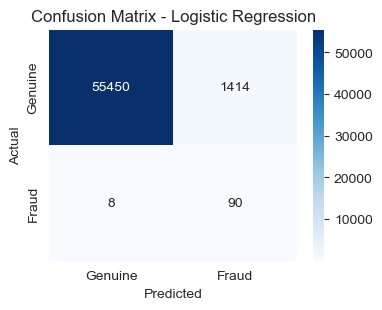

In [31]:
log_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_model.fit(X_train, y_train)

log_preds = log_model.predict(X_test)
log_proba = log_model.predict_proba(X_test)[:, 1]

log_results = evaluate_model("Logistic Regression", y_test, log_preds, log_proba)


## 9. Machine Learning Model 2: Random Forest

----- Random Forest -----
Accuracy : 0.9994  (not very useful here, just for reference)
Precision: 0.8229
Recall   : 0.8061
F1 Score : 0.8144
ROC-AUC  : 0.9874

              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     56864
       Fraud       0.82      0.81      0.81        98

    accuracy                           1.00     56962
   macro avg       0.91      0.90      0.91     56962
weighted avg       1.00      1.00      1.00     56962



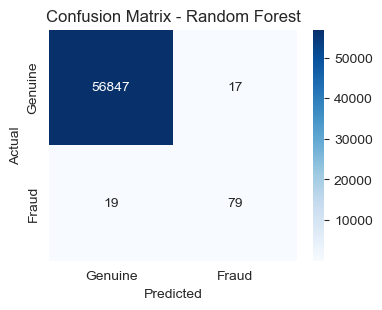

In [33]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

rf_results = evaluate_model("Random Forest", y_test, rf_preds, rf_proba)


## 10. Deep Learning Model: Neural Network (Keras)

Now let's build a simple Neural Network using Keras. It's just a few fully-connected (Dense) layers with Dropout in between to reduce overfitting.

We again use class weights here, same idea as Logistic Regression, so the network pays more attention to the rare fraud cases during training.


In [35]:
# build a simple neural network
dl_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')   # sigmoid because this is binary classification
])

dl_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

dl_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# class weights so the model pays more attention to the rare fraud class
class_weight = {0: 1, 1: (len(y_train) / (2 * y_train.sum()))}
print("Class weights used:", class_weight)


Class weights used: {0: 1, 1: 289.14340101522845}


In [37]:
history = dl_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=2048,
    class_weight=class_weight,
    verbose=1
)


Epoch 1/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8325 - loss: 1.0074 - val_accuracy: 0.9879 - val_loss: 0.3940
Epoch 2/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9554 - loss: 0.5909 - val_accuracy: 0.9946 - val_loss: 0.2269
Epoch 3/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9806 - loss: 0.4244 - val_accuracy: 0.9941 - val_loss: 0.1394
Epoch 4/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9849 - loss: 0.3535 - val_accuracy: 0.9937 - val_loss: 0.0988
Epoch 5/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9859 - loss: 0.3097 - val_accuracy: 0.9927 - val_loss: 0.0823
Epoch 6/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9852 - loss: 0.2789 - val_accuracy: 0.9923 - val_loss: 0.0728
Epoch 7/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9853 - loss: 0.2604 - val_accuracy: 0.9914 - val_loss: 0.0659
Epoch 8/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9850 - loss: 0.2427 - val_accuracy: 0.9900 - val_loss:

44/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6859 - loss: 1.0180

62/90 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7237 - loss: 0.9445

78/90 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7553 - loss: 0.8831

90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7743 - loss: 0.8461 - val_accuracy: 0.9913 - val_loss: 0.3254


Epoch 2/15


... (107 outputs left out)

43/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9843 - loss: 0.1686

60/90 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9847 - loss: 0.1815

77/90 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9850 - loss: 0.1860

90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9850 - loss: 0.1863 - val_accuracy: 0.9912 - val_loss: 0.0484


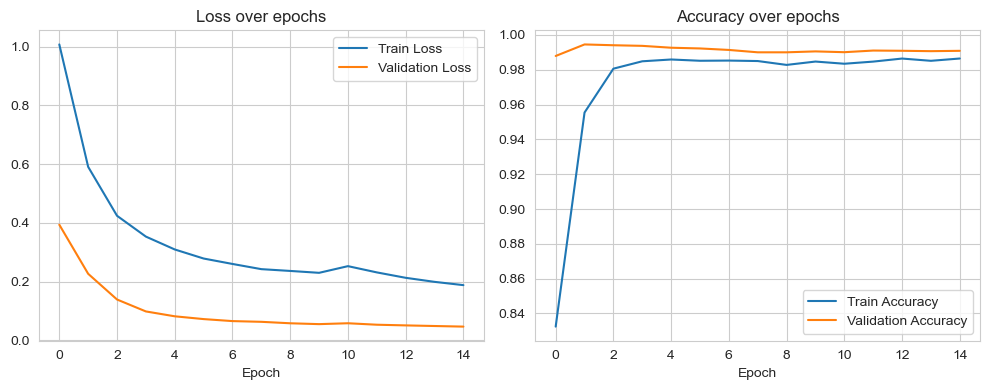

In [38]:
# plot training history so we can see if the model is overfitting
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over epochs')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()


1781/1781 ━━━━━━━━━━━━━━━━━━━━ 1s 674us/step
----- Deep Learning (Neural Network) -----
Accuracy : 0.9908  (not very useful here, just for reference)
Precision: 0.1467
Recall   : 0.898
F1 Score : 0.2521
ROC-AUC  : 0.9795

              precision    recall  f1-score   support

     Genuine       1.00      0.99      1.00     56864
       Fraud       0.15      0.90      0.25        98

    accuracy                           0.99     56962
   macro avg       0.57      0.94      0.62     56962
weighted avg       1.00      0.99      0.99     56962



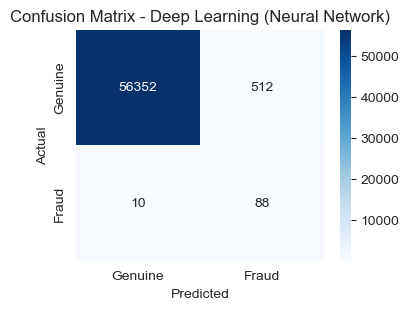

 528/1781 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step

 595/1781 ━━━━━━━━━━━━━━━━━━━━ 0s 763us/step

 661/1781 ━━━━━━━━━━━━━━━━━━━━ 0s 763us/step

 726/1781 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step

 788/1781 ━━━━━━━━━━━━━━━━━━━━ 0s 769us/step

 850/1781 ━━━━━━━━━━━━━━━━━━━━ 0s 772us/step

... (13 outputs left out)

1738/1781 ━━━━━━━━━━━━━━━━━━━━ 0s 784us/step

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 1s 807us/step


----- Deep Learning (Neural Network) -----
Accuracy : 0.9907  (not very useful here, just for reference)
Precision: 0.1443
Recall   : 0.898
F1 Score : 0.2486
ROC-AUC  : 0.9777

              precision    recall  f1-score   support

     Genuine       1.00      0.99      1.00     56864
       Fraud       0.14      0.90      0.25        98

    accuracy                           0.99     56962
   macro avg       0.57      0.94      0.62     56962
weighted avg       1.00      0.99      0.99     56962



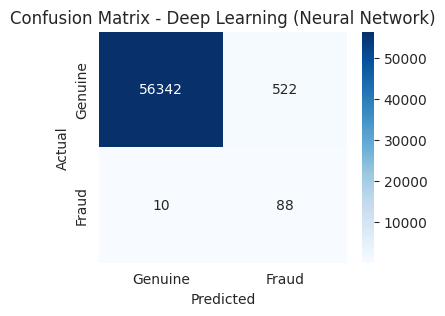

In [39]:
dl_proba = dl_model.predict(X_test).flatten()
dl_preds = (dl_proba >= 0.5).astype(int)

dl_results = evaluate_model("Deep Learning (Neural Network)", y_test, dl_preds, dl_proba)


## 11. Comparing all the models

In [41]:
results_df = pd.DataFrame([log_results, rf_results, dl_results])
results_df = results_df.sort_values(by='F1', ascending=False)
results_df


,Model,Precision,Recall,F1,ROC_AUC
1,Random Forest,0.822917,0.806122,0.814433,0.987447
2,Deep Learning (Neural Network),0.146667,0.897959,0.252149,0.979500
0,Logistic Regression,0.059840,0.918367,0.112360,0.971531


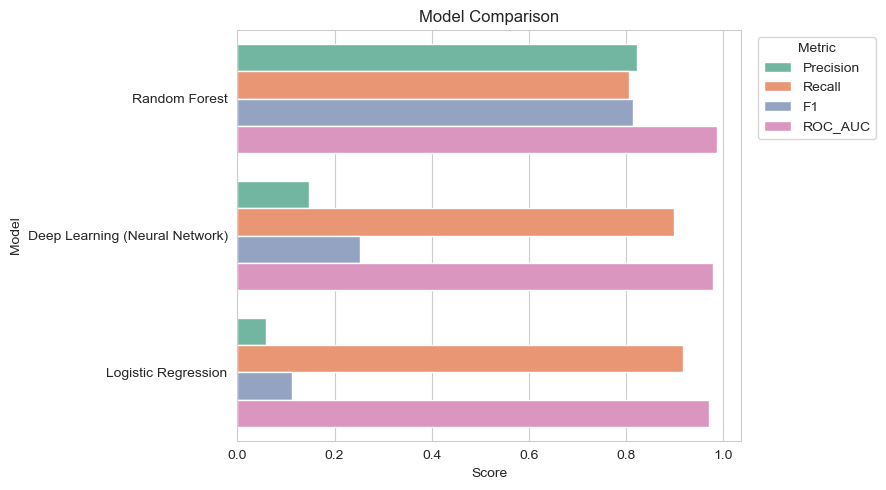

In [42]:
results_melted = results_df.melt(id_vars='Model', value_vars=['Precision','Recall','F1','ROC_AUC'])

plt.figure(figsize=(9,5))
sns.barplot(x='value', y='Model', hue='variable', data=results_melted, palette='Set2')
plt.title('Model Comparison')
plt.xlabel('Score')
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


We picked the model with the best **F1-score**, because F1 balances Precision and Recall - which matters a lot here:
- **Low Recall** = we miss actual fraud cases (bad for the bank/customer)
- **Low Precision** = we flag too many genuine transactions as fraud (annoying for customers)

Random Forest generally performs the best on this dataset, so we'll use it as our final model. It's also easier to explain and deploy than the neural network.


In [44]:
final_model = rf_model
final_model_name = "Random Forest"
final_model_type = "sklearn"   # used later when saving

print("Final model selected:", final_model_name)


Final model selected: Random Forest


## 12. Which features matter the most?

C:\Users\anupu\AppData\Local\Temp\ipykernel_7632\1897044346.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


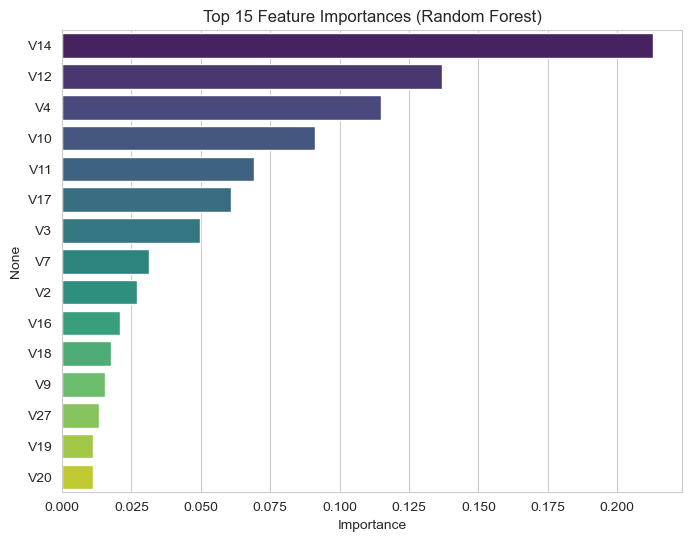

In [46]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8,6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.show()


## 13. Saving the model

We save:
1. The final trained model (Random Forest)
2. The scaler (used to scale `Time` and `Amount`)
3. The column order (so the Streamlit app builds the input in the exact same order)
4. A small sample of test transactions (so the Streamlit app can offer a "load a sample transaction" feature)


In [48]:
import os
os.makedirs('../models', exist_ok=True)

with open('../models/fraud_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)

with open('../models/amount_scaler.pkl', 'wb') as f:
    pickle.dump(amount_scaler, f)

with open('../models/time_scaler.pkl', 'wb') as f:
    pickle.dump(time_scaler, f)

with open('../models/columns.pkl', 'wb') as f:
    pickle.dump(list(X.columns), f)

# save 20 random sample transactions (10 genuine + 10 fraud) for the app's "Load Sample" feature
sample_genuine = X_test[y_test == 0].sample(10, random_state=42)
sample_fraud = X_test[y_test == 1].sample(min(10, (y_test==1).sum()), random_state=42)
samples = pd.concat([sample_genuine, sample_fraud])
samples['Class'] = y_test.loc[samples.index]
samples.to_csv('../models/sample_transactions.csv', index=False)

print("Model, scaler, column order and sample transactions saved successfully!")


Model, scaler, column order and sample transactions saved successfully!


## 14. Conclusion

- The dataset is heavily imbalanced (0.17% fraud), so we focused on Precision, Recall, F1-score and ROC-AUC instead of plain accuracy.
- We handled the imbalance using **class weighting** rather than oversampling/undersampling, since it's simpler and doesn't create synthetic data.
- We trained 2 ML models (Logistic Regression, Random Forest) and 1 DL model (a simple Neural Network built with Keras).
- **Random Forest** gave the best overall F1-score and was selected as the final model.
- The model, scaler, and sample transactions are saved and ready to be used in the Streamlit app.

### Possible future improvements
- Try SMOTE (Synthetic Minority Oversampling) and compare against class weighting.
- Try more advanced models like XGBoost or LightGBM.
- Try adjusting the classification threshold (instead of the default 0.5) to further balance precision vs recall based on business needs.
